# **Projet reconaissance voyelle**

### **Adel TAIDER et Nessim KOCAK**

In [13]:
#imports nécessaires pour le projet
import numpy as np
import msicpe.mana as mana
import msicpe.san as san
import pandas as pd
import msicpe.san as san
from plotly import express as px
import matplotlib.pyplot as plt
import scipy as signal

### Import d'un signal et affichage de son spectre

In [14]:
signal_dict = np.load('data partie 2/apprentissage/a_1.npz') # signal_dict est un dictionnaire
s = signal_dict['s'] # extraction du signal utile
t = signal_dict['t']        

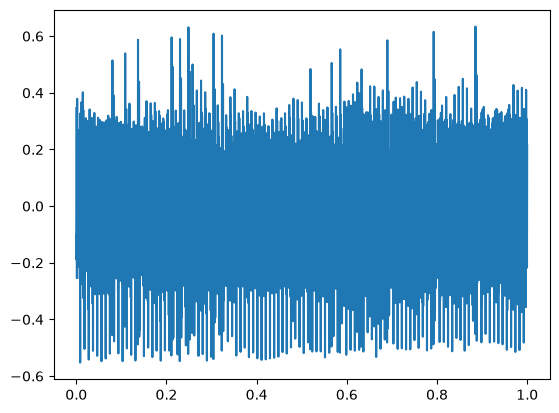

In [15]:
s_centre = s - np.mean(s) #on retire la composante continue du signal

plt.plot(t,s_centre)

In [16]:
nu, S = san.trans_fourier(s_centre, t) #TFD du signal

spectre = np.abs(S) #Module du signal pour tracer le spectre

df = pd.DataFrame({"nu": nu, "spectre": spectre})

fig = px.line(
    df, 
    x="nu", 
    y=["spectre"], 
    title="Courbe de la fonction"
)
fig.show()

### Affichage du spectre en échelle log

/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


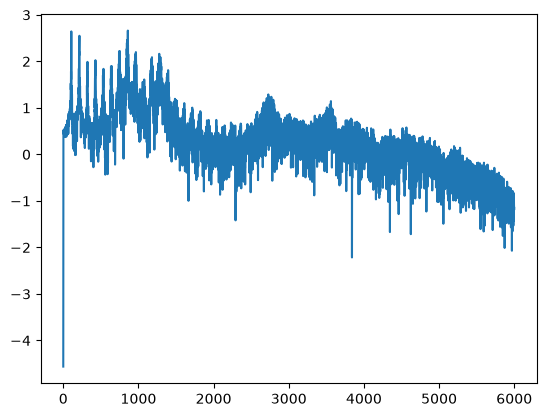

In [17]:
plt.plot(nu, np.log10(S))

### Création de la fonction pour extraire le vect d'un signal

In [18]:
def vect_signal(chemin, H):

    #import du signal
    dat = np.load(chemin)
    s = dat['s']
    t = dat['t']

    #on retire la composante continue du signal pour le centrer
    s = s - np.mean(s)

    #calcul de la TFD, du spectre et normalisation
    nu, sig = san.trans_fourier(s, t)
    spectre = np.abs(sig)
    spectre_norm = spectre / np.max(spectre)

    #détection de la fréq fondamentale f0
    f0 = san.detect_fondamentale(spectre_norm, nu)

    #création de la liste des H + 1 fréquences : [f0, 2*f0, ..., (H+1)*f0] avec foncdamentale incluse
    freq_list = []
    for k in range(1, H + 2):
        freq_list.append(k * f0)

    # Extraction des amplitudes des pics
    _, peak_amplitudes = san.detect_pics(spectre_norm, freq_list, nu)

    #renvoi du vecteur des amplitudes du spectre en échelle log
    return np.log10(peak_amplitudes)

### Fonction pour calculer les vecteurs moyens des voyelles

In [19]:
def vects_voyelles(voyelles,nb_sons,H) :
    
    dico_vects = {} #dico des voyelles avec key = voyelle et value = vect moyen

    for v in voyelles:
        vecteurs = np.zeros((nb_sons, H + 1)) #initialisation de la matrice de taille nb_sons*H+1 (on rajoute une colonne pour la fondamentale)

        for i in range(nb_sons):

            # Stockage des vecteurs de la voyelle dans la matrice ligne par ligne
            vecteurs[i] = vect_signal(f'data partie 2/apprentissage/{v}_{i+1}.npz',H)

        # Calcul du vect moyen de la voyelle et enregistrement dans le dico
        dico_vects[v] = np.mean(vecteurs, axis=0)

    return dico_vects

### Calcul et affichage graphique des vecteurs moyens des voyelles

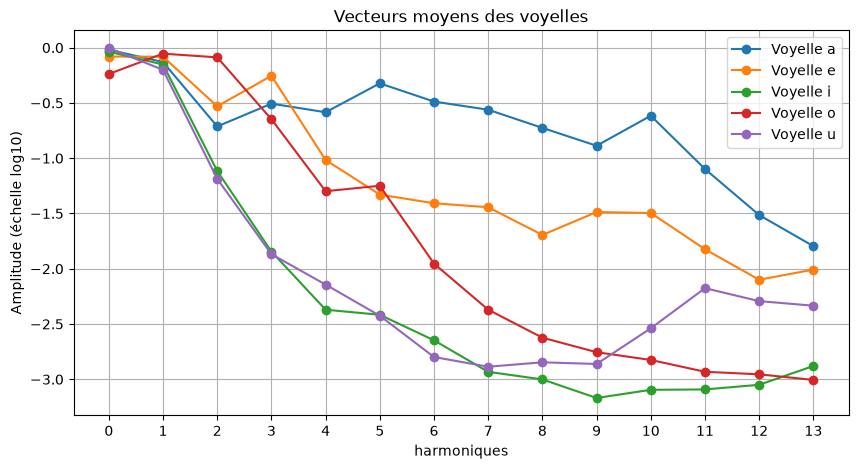

In [20]:
voyelles = ['a', 'e', 'i', 'o', 'u']
H = 13  # Nombre d'harmoniques
nb_sons = 5 #nombre de sons par harmonique

dico_vects = vects_voyelles(voyelles,nb_sons,H) #calcul des vects moyens

harmoniques = np.arange(0, H + 1) #axe des abcisses pour le tracé

plt.figure(figsize=(10, 5))

for v in voyelles : 
    plt.plot(
        harmoniques,
        dico_vects[v],
        '-o',
        label="Voyelle "+v,
    )
    
plt.title('Vecteurs moyens des voyelles')
plt.xlabel('harmoniques')
plt.ylabel('Amplitude (échelle log10)')
plt.xticks(harmoniques)
plt.grid(True)
plt.legend()
plt.show()

### Fonction pour le calcul des distances et pour déterminer la bonne voyelle

In [21]:
def test_signal(chemin,H,voyelles,nb_sons,print_dist) :

    distances_v =[] #liste des distances avec chaque voyelle
    indice_bonne_lettre = 0 #indice de la bonne lettre pour aller la chercher dans le dico ensuite
    equidistance = False #paramètre en cas des 2 vecteurs les plus proches à equidistance

    dico_vects = vects_voyelles(voyelles,nb_sons,H) #calcul des vects moyens

    vect_test = vect_signal(chemin,H) #calcul du vect du signal testé

    #calcul de la somme des valeurs absolues des distances point par point par rapport au vecteur moyen pour chaque voyelle
    for v in voyelles :
        distance = 0
        for i in range(len(vect_test)) :
            distance += np.abs(vect_test[i]-dico_vects[v][i])
        distances_v.append(float(distance))

    #comparaison des distances pour determiner la voyelle la plus proche
    for i in range(len(distances_v)) :
        if round(distances_v[i], 2) == round(np.min(distances_v), 2) and equidistance == False :
            indice_bonne_lettre = i
            equidistance = True

        #réccurence en auguementant le nb d'harmoniques si le signal est trop proche de 2 voyelles 
        elif round(distances_v[i], 2) == round(np.min(distances_v), 2) and equidistance == True :
            return test_signal(chemin,H+1,voyelles,nb_sons,print_dist)
        
    #affichage des distances de chaque voyelle si souhaité par l'utilisateur
    if print_dist :
        for i in range(len(distances_v))  :
            print("distance de ", voyelles[i], ":", distances_v[i])

    return "la voyelle plus proche est : "+ voyelles[indice_bonne_lettre]

### Test de notre stratégie sur tous les signaux de la base de test

In [22]:
for v in voyelles :
    for i in range(2) :
        print("TEST pour",v,"_",i+6)
        print(test_signal(f'data partie 2/test/{v}_{i+6}.npz',H,voyelles,nb_sons,False))


TEST pour a _ 6
la voyelle plus proche est : a
TEST pour a _ 7
la voyelle plus proche est : a
TEST pour e _ 6
la voyelle plus proche est : e
TEST pour e _ 7
la voyelle plus proche est : e
TEST pour i _ 6
la voyelle plus proche est : i
TEST pour i _ 7
la voyelle plus proche est : i
TEST pour o _ 6
la voyelle plus proche est : o
TEST pour o _ 7
la voyelle plus proche est : o
TEST pour u _ 6
la voyelle plus proche est : u
TEST pour u _ 7
la voyelle plus proche est : u


### Application de notre stratégie au signal d'étude et tracé de son vecteur

distance de  a : 22.455273146554827
distance de  e : 15.567131682965554
distance de  i : 2.614219132065773
distance de  o : 7.655914113484323
distance de  u : 4.540247097425162
la voyelle plus proche est : i


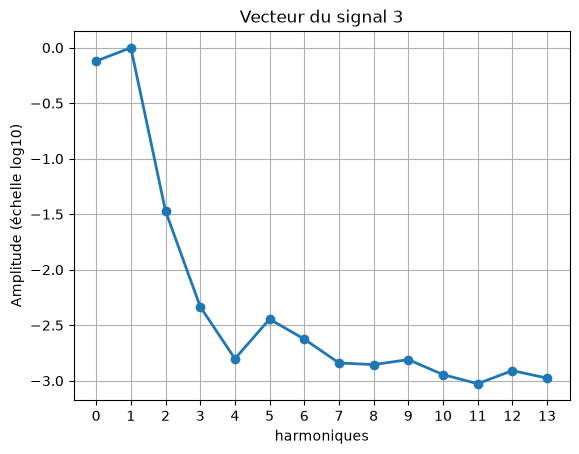

In [23]:
etude = test_signal('data partie 2/etude/BON_signal_3.npz',H,voyelles,nb_sons,True)

print(etude)

plt.plot(
        harmoniques,
        vect_signal('data partie 2/etude/BON_signal_3.npz',H),
        '-o',
        linewidth=2,
        label="signal 3",
    )

plt.title('Vecteur du signal 3')
plt.xlabel('harmoniques')
plt.ylabel('Amplitude (échelle log10)')
plt.xticks(harmoniques)
plt.grid(True)
plt.show()

### Tracé du vecteur du signal d'étude avec les vecteurs moyens des voyelles 

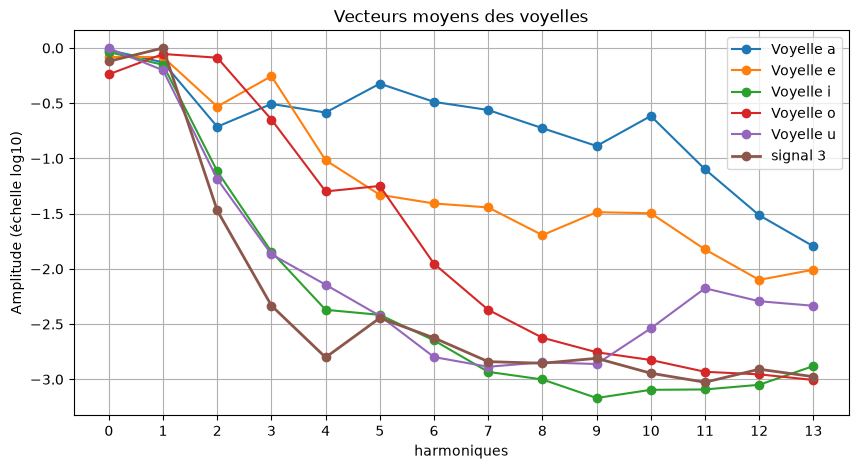

In [24]:
plt.figure(figsize=(10, 5))

#vecteurs moyens 
for v in voyelles : 
    plt.plot(
        harmoniques,
        dico_vects[v],
        '-o',
        label="Voyelle "+v,
    )

#vect du signal 3
plt.plot(
        harmoniques,
        vect_signal('data partie 2/etude/BON_signal_3.npz',H),
        '-o',
        linewidth=2,
        label="signal 3",
    )

plt.title('Vecteurs moyens des voyelles')
plt.xlabel('harmoniques')
plt.ylabel('Amplitude (échelle log10)')
plt.xticks(harmoniques)
plt.grid(True)
plt.legend()
plt.show()